# Đánh giá B0 VGG16–GeM: checkpoint tốt nhất tại epoch 12

Notebook tổng hợp bằng chứng training, kiểm chứng kết quả đã lưu và tạo hình/bảng dùng cho thuyết trình.

**Tiêu chí chọn model:** validation loss thấp nhất, cố định **epoch 12**; không chọn lại checkpoint dựa vào mAP trên test.

**Cấu trúc**

1. Cấu hình, đường dẫn và nguồn dữ liệu.
2. Kiểm tra artifact, checkpoint và protocol.
3. Learning curves: loss, generalization gap, GeM `p`, learning rate, thời gian.
4. mAP theo epoch và kết quả checkpoint 12.
5. Phân bố AP, query khó/dễ, thay đổi so với epoch khác.
6. Xuất tài liệu cho thuyết trình.
7. Chạy lại benchmark từ `best.pt` (tùy chọn, cần dataset và PyTorch).
8. Precision–recall và ảnh retrieval từ ranking thực tế (khi đã chạy mục 7).

**Hai loại bằng chứng:** Mục 1–6 phân tích JSON/log của run đã xuất từ Kaggle; đây không phải một lần inference mới. Mục 7–8 chạy inference thực tế, crop query và xếp hạng lại. Chỉ có AP đã lưu thì không suy ra được ranking, P@k hoặc precision–recall curve.

Để chạy mục 1–6 cần `numpy`, `pandas`, `matplotlib`, `IPython` và ZIP artefact đã giải nén. Để chạy inference lại cần thêm `torch`, `torchvision`, `Pillow` và ảnh benchmark. File/hình mới được xuất vào `outputs/b0-evaluation/epoch_012/` (ngoài Git).


## 1. Cấu hình và đọc dữ liệu

Chạy notebook từ repo hoặc thư mục con. Giải nén ZIP artefact vào `outputs/B0_VGG16_GeM_Evaluation/`, hoặc đặt `ARTIFACT_ROOT_OVERRIDE` tới thư mục đã giải nén. `PROJECT_ROOT_OVERRIDE` và `OUTPUT_DIR_OVERRIDE` là tùy chọn. Notebook không tải dataset/model qua mạng. Các output lưu trong file này là bằng chứng của lần chạy lịch sử.


In [1]:
from pathlib import Path
import os
import hashlib
import json
import pickletools
import re
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT_OVERRIDE = None  # Repo root, nếu không chạy notebook từ trong repo.
ARTIFACT_ROOT_OVERRIDE = None  # Thư mục B0_VGG16_GeM_Evaluation đã giải nén, hoặc Kaggle output root.
OUTPUT_DIR_OVERRIDE = None  # Mặc định: repo/outputs/b0-evaluation/epoch_012.
LATEST_RESUME_CHECKPOINT_OVERRIDE = None  # Tùy chọn; không có trong ZIP evidence.
BEST_EPOCH = 12
RERUN_BENCHMARK = False
# Nếu chạy lại, cung cấp các đường dẫn chứa gnd_*.pkl và thư mục jpg.
BENCHMARK_DIRS = {'oxford5k': None, 'paris6k': None}
QUERY_NAMES = {'oxford5k': None, 'paris6k': None}  # Tùy chọn: danh sách 55 tên theo qimlist.

def find_project_root():
    if PROJECT_ROOT_OVERRIDE is not None:
        return Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'README.md').is_file() and (p / 'reproduction/B0/epoch_012').is_dir():
            return p
    raise FileNotFoundError('Không tìm được project. Hãy đặt PROJECT_ROOT_OVERRIDE.')

ROOT = find_project_root()
ARTIFACT_ROOT = (Path(ARTIFACT_ROOT_OVERRIDE).expanduser().resolve() if ARTIFACT_ROOT_OVERRIDE
                 else ROOT / 'outputs/B0_VGG16_GeM_Evaluation')
RUN_DIR = (ARTIFACT_ROOT / 'run_artifacts' if (ARTIFACT_ROOT / 'run_artifacts').is_dir()
           else ARTIFACT_ROOT / 'runs/b0_sfm100_vgg16_gem')
SOURCE_DIR = (ARTIFACT_ROOT / 'source' if (ARTIFACT_ROOT / 'source').is_dir()
              else ARTIFACT_ROOT / 'source_747166e627e5')
if not (RUN_DIR / 'run_record.json').is_file():
    raise FileNotFoundError(f'Không tìm thấy run_record.json trong {RUN_DIR}; giải nén ZIP hoặc đặt ARTIFACT_ROOT_OVERRIDE.')
BEST_CHECKPOINT = RUN_DIR / 'best.pt'
OUT_DIR = (Path(OUTPUT_DIR_OVERRIDE).expanduser().resolve() if OUTPUT_DIR_OVERRIDE
           else ROOT / 'outputs/b0-evaluation' / f'epoch_{BEST_EPOCH:03d}')
LATEST_RESUME_CHECKPOINT = (Path(LATEST_RESUME_CHECKPOINT_OVERRIDE).expanduser().resolve()
                            if LATEST_RESUME_CHECKPOINT_OVERRIDE else ARTIFACT_ROOT.parent / 'latest_resume.pt')
FIG_DIR = OUT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
DATASETS = ['oxford5k', 'paris6k']
LABELS = {'oxford5k': 'Oxford5k', 'paris6k': 'Paris6k'}
COLORS = {'oxford5k': '#2563eb', 'paris6k': '#e87924'}

def read_json(p):
    return json.loads(Path(p).read_text())

def sha256(p):
    h = hashlib.sha256()
    with Path(p).open('rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

record = read_json(RUN_DIR / 'run_record.json')
history = pd.DataFrame(read_json(RUN_DIR / 'history.json')).sort_values('epoch').reset_index(drop=True)
saved_evals = {int(p.stem.rsplit('_', 1)[1]): read_json(p)
               for p in sorted(RUN_DIR.glob('evaluation_epoch_*.json'))}
selected_eval = saved_evals[BEST_EPOCH]
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 220, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})

def save_figure(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png', bbox_inches='tight')
    fig.savefig(FIG_DIR / f'{name}.svg', bbox_inches='tight')
    plt.show()
    plt.close(fig)

display(Markdown(f'**Project:** `{ROOT}`  \n**Run:** `{RUN_DIR.name}`  \n**Checkpoint chọn:** epoch {BEST_EPOCH}  \n**Export:** `{OUT_DIR}`'))


/tmp/gem-evaluation-venv/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


**Project:** `/home/dacekey/SEG301_Fall26/research`  
**Run:** `b0_sfm100_vgg16_gem`  
**Checkpoint chọn:** epoch 12  
**Export:** `/home/dacekey/SEG301_Fall26/research/reproduce/evaluation_results/epoch_012`

## 2. Kiểm tra artifact và cấu hình thực nghiệm

Kiểm tra loss hữu hạn, số query, tính nhất quán mAP với AP, protocol và metadata checkpoint. Đọc metadata epoch bằng `pickletools` không thực thi pickle và không cần cài PyTorch. Phép kiểm tra này xác nhận epoch trong file; chưa thay thế việc load model và inference ở mục 7.


In [2]:
def checkpoint_epoch(path):
    with zipfile.ZipFile(path) as archive:
        data_name = next(n for n in archive.namelist() if n.endswith('data.pkl'))
        ops = list(pickletools.genops(archive.read(data_name)))
    # Key epoch đầu tiên là trường top-level; các epoch sau có thể thuộc history.
    for i, (_, arg, _) in enumerate(ops):
        if arg == 'epoch':
            for op, value, _ in ops[i + 1:i + 5]:
                if op.name in {'BININT', 'BININT1', 'BININT2', 'INT', 'LONG1'}:
                    return int(value)
    raise ValueError(f'Không đọc được epoch: {path}')

assert not history.epoch.duplicated().any()
assert history.epoch.tolist() == list(range(1, int(history.epoch.max()) + 1))
assert np.isfinite(history[['train_loss', 'val_loss', 'gem_p', 'seconds_train_val']]).all().all()
assert int(history.loc[history.val_loss.idxmin(), 'epoch']) == BEST_EPOCH
assert checkpoint_epoch(BEST_CHECKPOINT) == BEST_EPOCH
assert selected_eval['label'] == f'epoch_{BEST_EPOCH}'
for epoch, ev in saved_evals.items():
    assert ev['protocol'] == 'legacy_ok_junk'
    assert ev['scale'] == [1] and not ev['whitening'] and not ev['query_expansion']
    assert ev['image_size'] == record['config']['eval_image_size']
    assert ev['source_commit'] == record['source_commit']
    for ds in DATASETS:
        vals = np.asarray(ev['datasets'][ds]['aps'], dtype=float)
        assert len(vals) == record['dataset_identity'][ds]['queries']
        assert np.isfinite(vals).all() and ((vals >= 0) & (vals <= 1 + 1e-12)).all()
        assert np.isclose(vals.mean(), ev['datasets'][ds]['map'], atol=1e-12, rtol=0)
        assert np.isclose(vals.mean() * 100, ev['datasets'][ds]['map_percent'], atol=1e-10, rtol=0)
assert sha256(SOURCE_DIR / 'cirtorch/utils/evaluate.py') == record['source_hashes']['cirtorch/utils/evaluate.py']

checkpoint_table = pd.DataFrame([
    {'file': os.path.relpath(p, ROOT), 'epoch': checkpoint_epoch(p), 'MB': p.stat().st_size / 1e6}
    for p in [BEST_CHECKPOINT, RUN_DIR / 'latest.pt', LATEST_RESUME_CHECKPOINT]
    if p.exists()
])
display(checkpoint_table.round(2))

train_info = record['dataset_identity']['partitions']['train']
val_info = record['dataset_identity']['partitions']['val']
config_table = pd.DataFrame([
    ('Backbone / pooling / descriptor', 'VGG16 / GeM shared trainable p / L2 512-D'),
    ('Train subset', f"{train_info['clusters']} clusters; {train_info['images']:,} images; seed {record['config']['seed']}"),
    ('Validation subset', f"{val_info['clusters']} clusters; {val_info['images']:,} images"),
    ('Epoch hoàn tất / kế hoạch', f"{int(history.epoch.max())} / {record['config']['epochs']}"),
    ('Selection', record['config']['selection']),
    ('Optimizer / initial LR', f"{record['config']['optimizer']} / {record['config']['lr']}"),
    ('Contrastive margin', record['config']['loss_margin']),
    ('Mining pool thực tế', record['actual_train_pool']),
    ('Tuples train / val mỗi epoch', f"{record['processed_train_tuples']} / {record['processed_val_tuples']}"),
    ('Eval image size / scale', f"{selected_eval['image_size']} / {selected_eval['scale']}"),
    ('Protocol / whitening / QE', 'Oxford5k & Paris6k legacy / OFF / OFF'),
    ('GPU / precision', f"{record['environment']['gpu']} / {record['precision']}"),
    ('Source commit', record['source_commit']),
], columns=['setting', 'value'])
display(config_table)
print('PASS: epoch 12 là best theo validation loss; tất cả JSON mAP = mean(AP).')


,file,epoch,MB
0,reproduce/output_kaggle/b0_sfm100_notebook/run...,12,176.63
1,reproduce/output_kaggle/b0_sfm100_notebook/run...,14,176.63
2,reproduce/output_kaggle/latest_resume.pt,7,176.62


,setting,value
0,Backbone / pooling / descriptor,VGG16 / GeM shared trainable p / L2 512-D
1,Train subset,"100 clusters; 15,953 images; seed 42"
2,Validation subset,20 clusters; 739 images
3,Epoch hoàn tất / kế hoạch,14 / 100
4,Selection,validation_loss
5,Optimizer / initial LR,adam / 1e-06
6,Contrastive margin,0.7
7,Mining pool thực tế,15953
8,Tuples train / val mỗi epoch,2000 / 180
9,Eval image size / scale,1024 / [1]


PASS: epoch 12 là best theo validation loss; tất cả JSON mAP = mean(AP).


### Đọc protocol và giới hạn dữ liệu

- Query được crop theo bounding box; gallery giữ ảnh đầy đủ. Resize và normalization phải khớp source khi chạy lại.
- Legacy ground truth dùng `ok` làm positives, `junk` loại khỏi ranking trước khi tính AP.
- AP được tính theo tích phân hình thang của source `compute_ap`, không dùng trực tiếp `sklearn.average_precision_score` thay thế.
- mAP là trung bình AP theo query, không phải accuracy phân loại. Các query cùng landmark có thể tương quan; bảng thống kê dưới đây mang tính mô tả, không tuyên bố ý nghĩa thống kê giữa các model.
- Run dùng SfM subset-100; không đồng nhất với training trên toàn bộ SfM-120k. Chỉ có evaluation epoch 8–14, nên không có mAP trước fine-tuning hoặc epoch 1–7 để vẽ thêm.


## 3. Learning curves — Model học như thế nào?

Đường loss lấy từ các epoch hoàn tất; phần epoch 15 dang dở không được gộp thành một epoch đầy đủ. Train/val loss có thể thay đổi do hard-negative mining thay đổi tuple mỗi epoch. Generalization gap là `val_loss − train_loss`, giúp theo dõi hai đường loss nhưng không phải bằng chứng độc lập để kết luận overfitting.


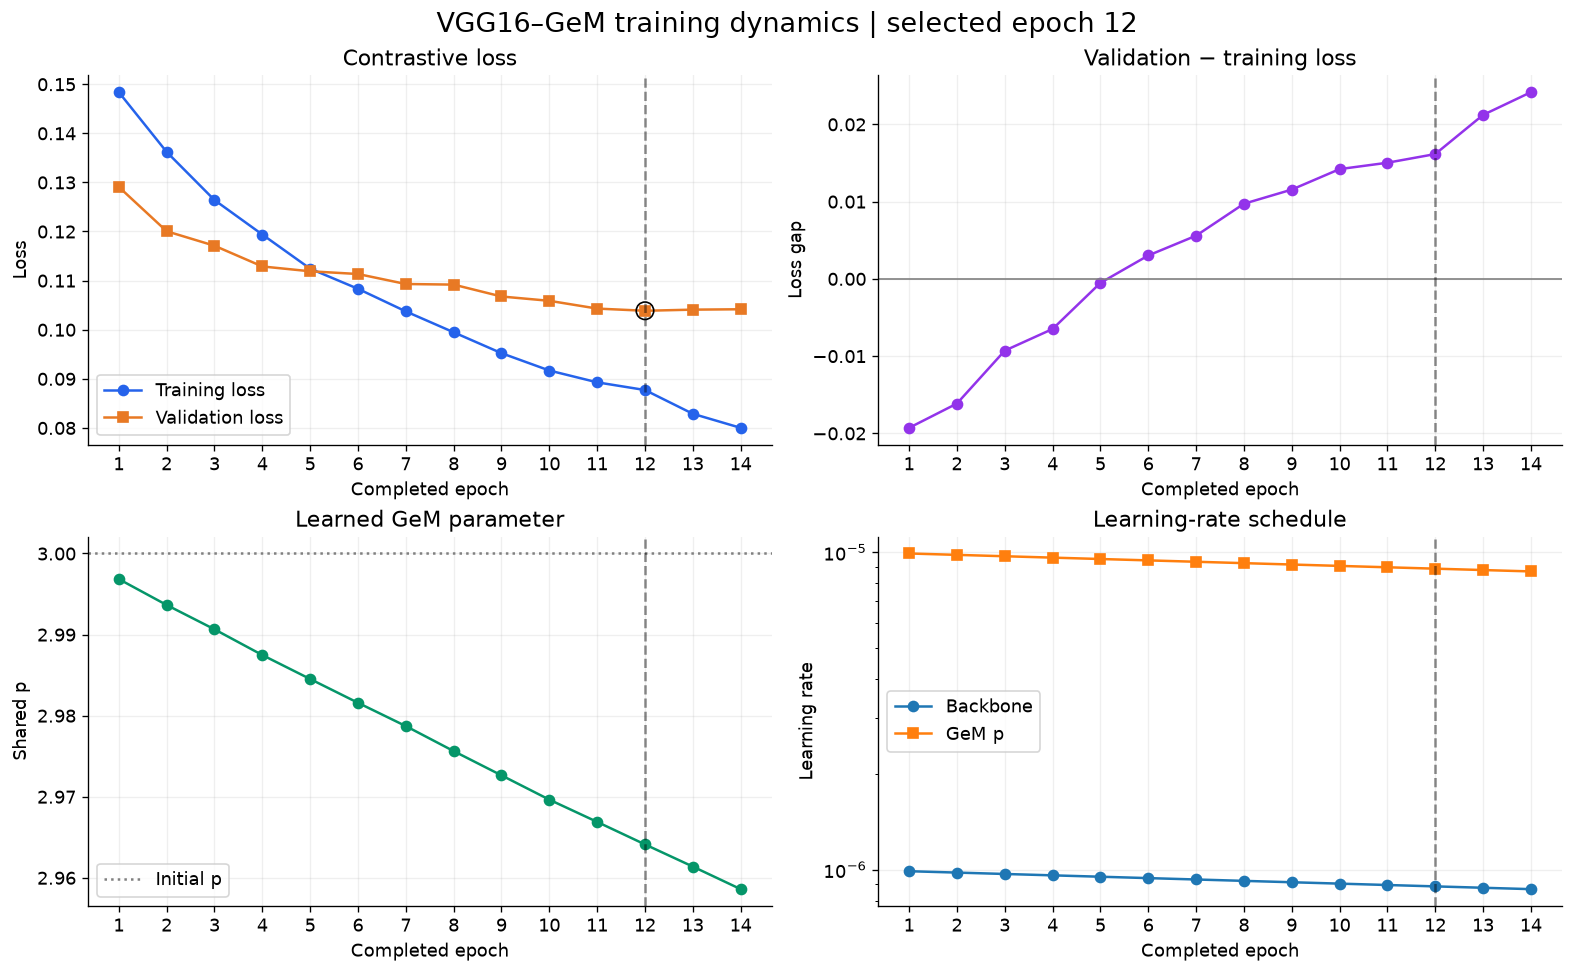

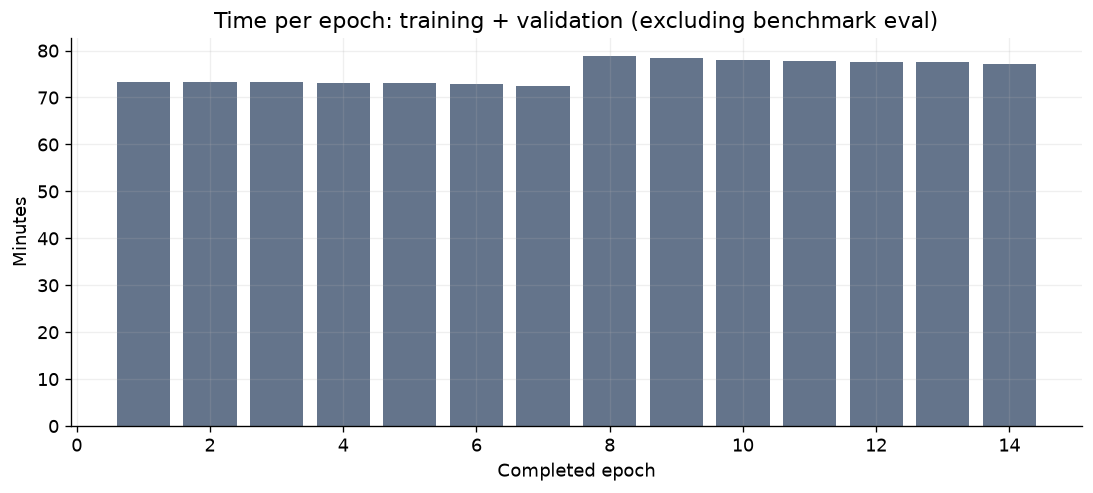

,epoch,train_loss,val_loss,loss_gap,gem_p,lr_backbone,lr_gem,train_val_minutes
0,1,0.148362,0.129066,-0.019297,2.996840,0.000001,0.000010,73.352546
1,2,0.136192,0.120040,-0.016152,2.993646,0.000001,0.000010,73.264084
2,3,0.126392,0.117089,-0.009303,2.990643,0.000001,0.000010,73.263942
3,4,0.119372,0.112872,-0.006500,2.987470,0.000001,0.000010,73.167923
4,5,0.112421,0.111888,-0.000533,2.984513,0.000001,0.000010,73.105417
5,6,0.108320,0.111333,0.003013,2.981579,0.000001,0.000009,72.912449
6,7,0.103718,0.109295,0.005578,2.978704,0.000001,0.000009,72.406581
7,8,0.099465,0.109174,0.009710,2.975620,0.000001,0.000009,78.731964
8,9,0.095209,0.106753,0.011543,2.972627,0.000001,0.000009,78.390812
9,10,0.091680,0.105875,0.014196,2.969629,0.000001,0.000009,77.945707


In [3]:
selected_row = history.set_index('epoch').loc[BEST_EPOCH]
history['loss_gap'] = history.val_loss - history.train_loss
history['lr_backbone'] = history.lr.apply(lambda x: x[0])
history['lr_gem'] = history.lr.apply(lambda x: x[1])
history['train_val_minutes'] = history.seconds_train_val / 60

fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
ax = axes[0, 0]
ax.plot(history.epoch, history.train_loss, 'o-', label='Training loss', color='#2563eb')
ax.plot(history.epoch, history.val_loss, 's-', label='Validation loss', color='#e87924')
ax.scatter([BEST_EPOCH], [selected_row.val_loss], s=110, facecolors='none', edgecolors='black', zorder=5)
ax.set(title='Contrastive loss', ylabel='Loss'); ax.legend()
axes[0, 1].plot(history.epoch, history.loss_gap, 'o-', color='#9333ea')
axes[0, 1].axhline(0, color='gray', lw=1)
axes[0, 1].set(title='Validation − training loss', ylabel='Loss gap')
axes[1, 0].plot(history.epoch, history.gem_p, 'o-', color='#059669')
axes[1, 0].axhline(record['config']['gem_p'], linestyle=':', color='gray', label='Initial p')
axes[1, 0].set(title='Learned GeM parameter', ylabel='Shared p'); axes[1, 0].legend()
axes[1, 1].semilogy(history.epoch, history.lr_backbone, 'o-', label='Backbone')
axes[1, 1].semilogy(history.epoch, history.lr_gem, 's-', label='GeM p')
axes[1, 1].set(title='Learning-rate schedule', ylabel='Learning rate'); axes[1, 1].legend()
for ax in axes.flat:
    ax.axvline(BEST_EPOCH, color='black', linestyle='--', alpha=.45)
    ax.set_xlabel('Completed epoch'); ax.set_xticks(history.epoch)
fig.suptitle('VGG16–GeM training dynamics | selected epoch 12', fontsize=16)
save_figure(fig, '01_learning_curves')

fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
ax.bar(history.epoch, history.train_val_minutes, color='#64748b')
ax.set(xlabel='Completed epoch', ylabel='Minutes', title='Time per epoch: training + validation (excluding benchmark eval)')
save_figure(fig, '02_epoch_runtime')
display(history[['epoch', 'train_loss', 'val_loss', 'loss_gap', 'gem_p', 'lr_backbone', 'lr_gem', 'train_val_minutes']].round(6))


In [4]:
first, last = history.iloc[0], history.iloc[-1]
train_drop = (first.train_loss - last.train_loss) / first.train_loss * 100
val_drop = (first.val_loss - last.val_loss) / first.val_loss * 100
training_log = (RUN_DIR / 'training.log').read_text(errors='replace')
last_train_matches = re.findall(r'Train: \[(\d+)\]\[(\d+)/(\d+)\]', training_log)
last_progress = '/'.join(last_train_matches[-1]) if last_train_matches else 'không đọc được'
display(Markdown(f"""
**Diễn giải để thuyết trình**

- Từ epoch {int(first.epoch)} đến {int(last.epoch)}, training loss giảm **{train_drop:.1f}%**, validation loss giảm **{val_drop:.1f}%**.
- Validation loss thấp nhất tại epoch **{BEST_EPOCH}: {selected_row.val_loss:.5f}**. Epoch 13–14 tăng nhẹ; có dấu hiệu chững lại nhưng chưa đủ bằng chứng kết luận overfitting hay hội tụ hoàn toàn.
- GeM `p` giảm từ initialization **{record['config']['gem_p']:.3f}** xuống **{selected_row.gem_p:.4f}** tại epoch 12: pooling đã được học; độ giảm nhỏ không tự chứng minh mức đóng góp của GeM nếu chưa có ablation.
- Trung bình training + validation: **{history.train_val_minutes.mean():.1f} phút/epoch**, chưa tính benchmark evaluation. Không dự đoán thời gian training hoàn tất từ riêng con số này.
- Mốc batch cuối trong log: **epoch/batch/total = {last_progress}**. Đây là snapshot đã xuất, không phải trạng thái trực tiếp của Kaggle.
"""))



**Diễn giải để thuyết trình**

- Từ epoch 1 đến 14, training loss giảm **46.1%**, validation loss giảm **19.3%**.
- Validation loss thấp nhất tại epoch **12: 0.10385**. Epoch 13–14 tăng nhẹ; có dấu hiệu chững lại nhưng chưa đủ bằng chứng kết luận overfitting hay hội tụ hoàn toàn.
- GeM `p` giảm từ initialization **3.000** xuống **2.9641** tại epoch 12: pooling đã được học; độ giảm nhỏ không tự chứng minh mức đóng góp của GeM nếu chưa có ablation.
- Trung bình training + validation: **75.5 phút/epoch**, chưa tính benchmark evaluation. Không dự đoán thời gian training hoàn tất từ riêng con số này.
- Mốc batch cuối trong log: **epoch/batch/total = 15/30/400**. Đây là snapshot đã xuất, không phải trạng thái trực tiếp của Kaggle.


## 4. Kết quả retrieval — mAP theo epoch và checkpoint 12

Đường mAP chỉ nối các epoch có JSON evaluation. Vạch epoch 12 là lựa chọn theo validation loss. Không thay tiêu chí chọn checkpoint bằng điểm test cao hơn ở epoch khác.


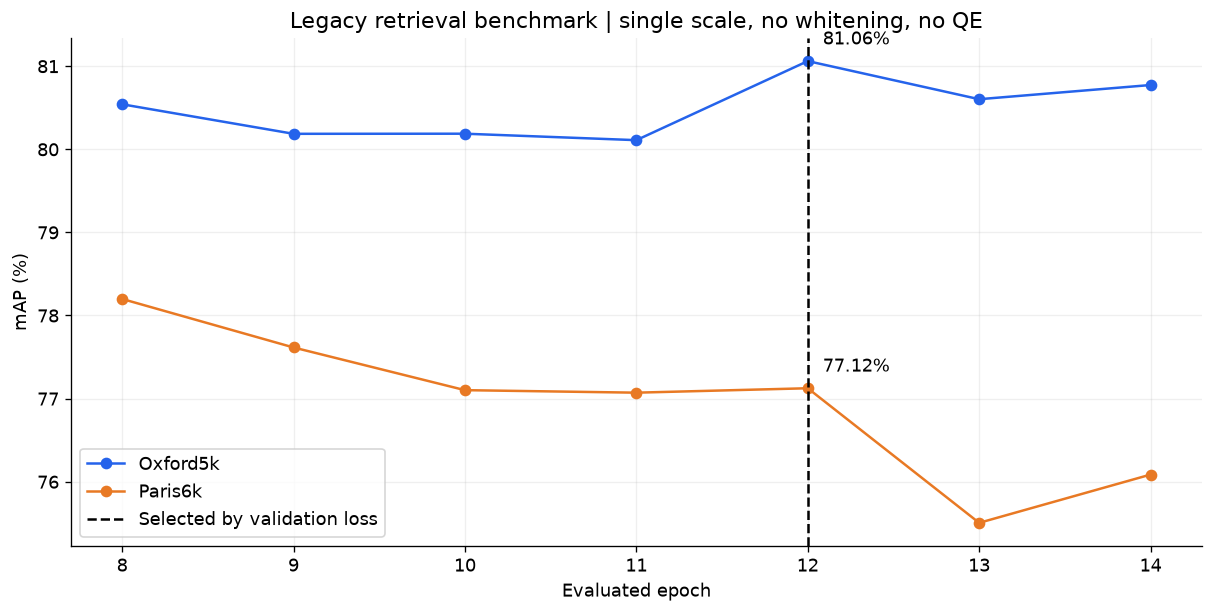

,dataset,epoch,gallery_images,queries,mAP_percent
0,Oxford5k,12,5063,55,81.0605
1,Paris6k,12,6392,55,77.1237


dataset,oxford5k,paris6k
epoch,,
8,80.5407,78.1980
9,80.1853,77.6144
10,80.1867,77.1008
11,80.1090,77.0705
12,81.0605,77.1237
13,80.6017,75.5042
14,80.7725,76.0850


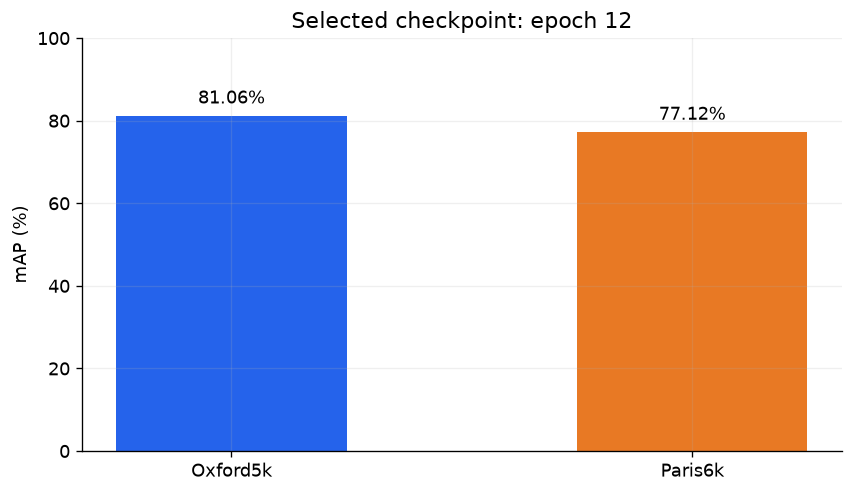

In [5]:
eval_rows = [{'epoch': epoch, 'dataset': ds, 'mAP_percent': ev['datasets'][ds]['map_percent']}
             for epoch, ev in sorted(saved_evals.items()) for ds in DATASETS]
eval_table = pd.DataFrame(eval_rows)
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
for ds in DATASETS:
    part = eval_table[eval_table.dataset == ds]
    ax.plot(part.epoch, part.mAP_percent, 'o-', label=LABELS[ds], color=COLORS[ds])
    val = selected_eval['datasets'][ds]['map_percent']
    ax.annotate(f'{val:.2f}%', (BEST_EPOCH, val), xytext=(9, 10), textcoords='offset points')
ax.axvline(BEST_EPOCH, linestyle='--', color='black', label='Selected by validation loss')
ax.set(xlabel='Evaluated epoch', ylabel='mAP (%)', title='Legacy retrieval benchmark | single scale, no whitening, no QE')
ax.set_xticks(sorted(saved_evals)); ax.legend()
save_figure(fig, '03_map_by_epoch')

benchmark_summary = pd.DataFrame([
    {'dataset': LABELS[ds], 'epoch': BEST_EPOCH,
     'gallery_images': record['dataset_identity'][ds]['gallery'],
     'queries': len(selected_eval['datasets'][ds]['aps']),
     'mAP_percent': selected_eval['datasets'][ds]['map_percent']}
    for ds in DATASETS
])
display(benchmark_summary.round(4))
display(eval_table.pivot(index='epoch', columns='dataset', values='mAP_percent').round(4))
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
bars = ax.bar(benchmark_summary.dataset, benchmark_summary.mAP_percent,
              color=[COLORS[ds] for ds in DATASETS], width=.5)
ax.bar_label(bars, fmt='%.2f%%', padding=5)
ax.set(ylim=(0, 100), ylabel='mAP (%)', title='Selected checkpoint: epoch 12')
save_figure(fig, '04_best_epoch_map')


## 5. Phân tích AP theo query

AP được hiển thị theo phần trăm. `query_index_0based` giữ đúng thứ tự AP trong JSON. Nếu chưa có ground truth/tên query, chỉ dùng mã `query_000`...; không gán tên landmark theo phỏng đoán. Độ lệch chuẩn dùng `ddof=0` để mô tả toàn bộ query của benchmark.


,dataset,n_queries,mean_AP_percent,median_AP_percent,std_AP_pp,min_AP_percent,q25_AP_percent,q75_AP_percent,max_AP_percent,AP_below_50_count,AP_at_least_90_count
0,Oxford5k,55,81.06,85.54,15.35,36.94,69.85,94.04,100.00,2,16
1,Paris6k,55,77.12,79.69,13.78,31.05,71.00,87.61,94.15,2,6


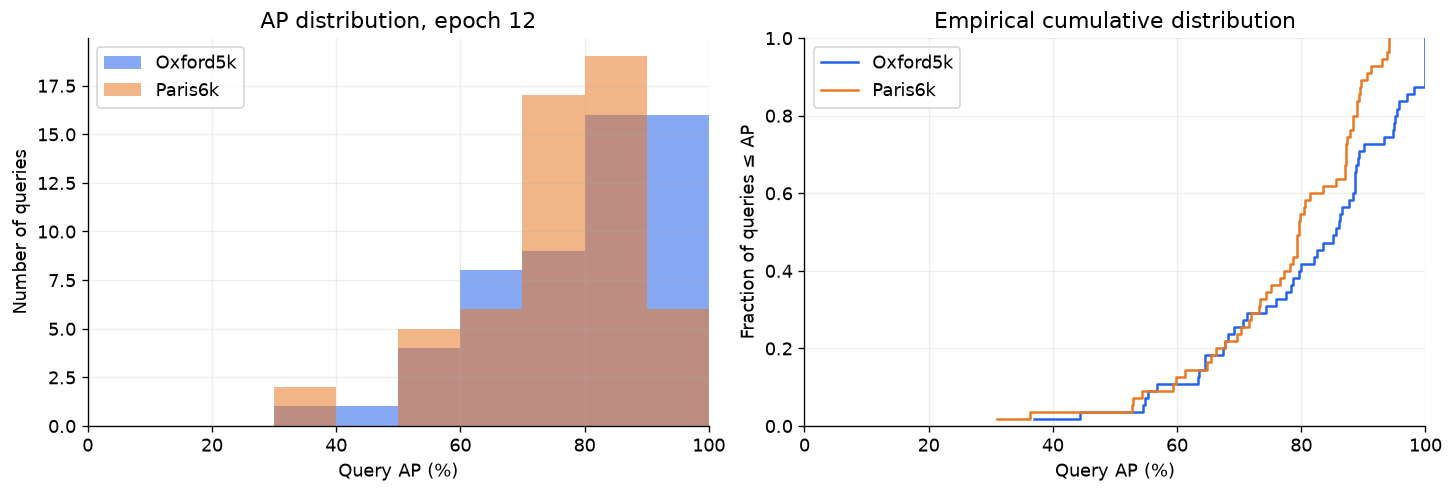

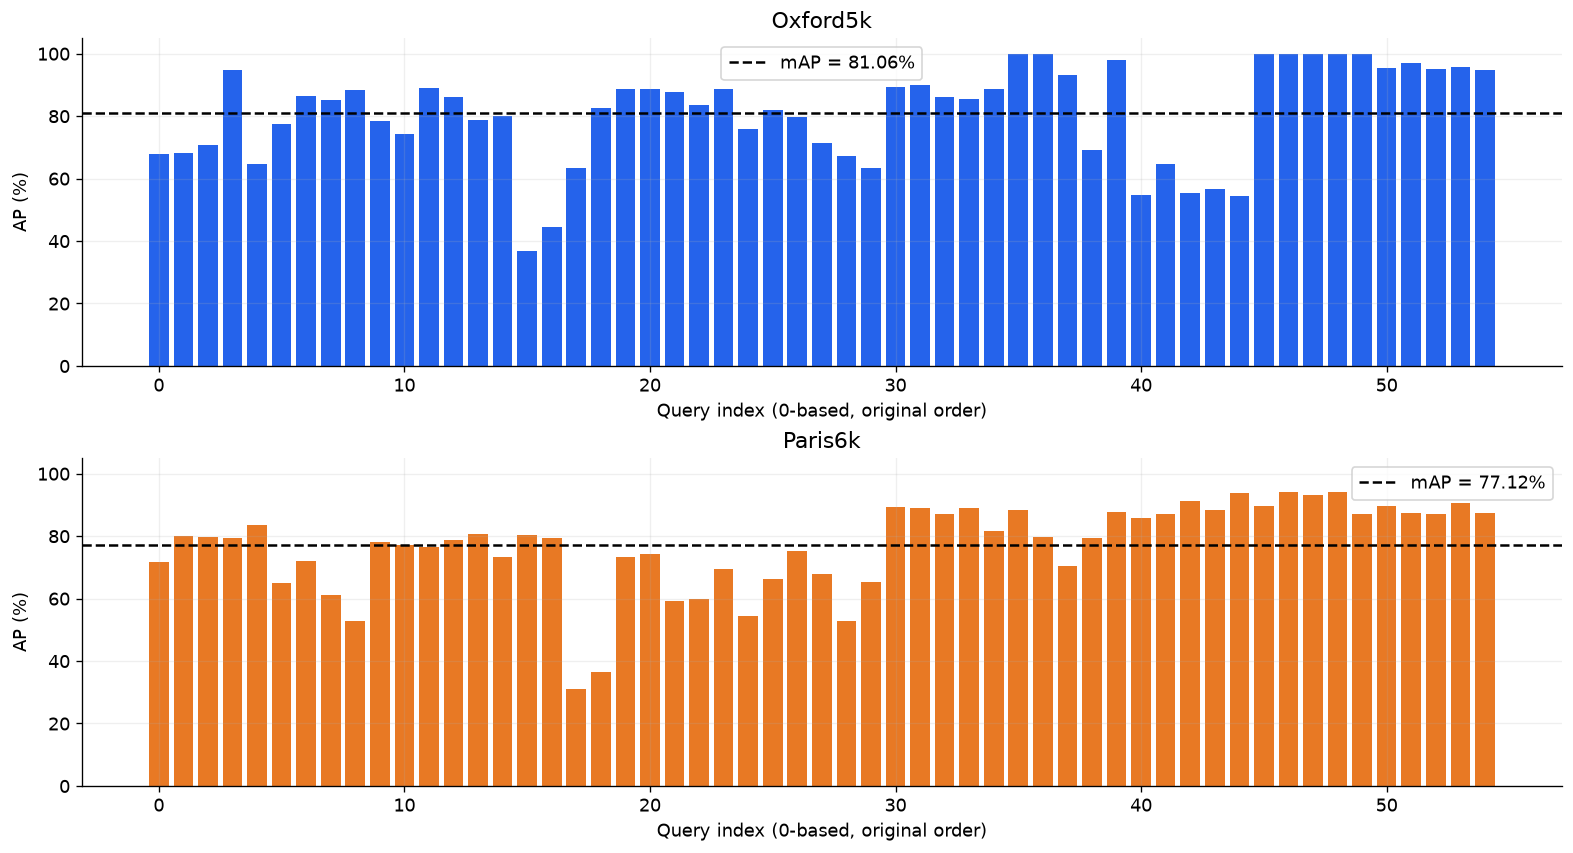

,dataset,query_index_0based,query_name,AP_percent,group
0,oxford5k,15,query_015,36.94,5 lowest AP
1,oxford5k,16,query_016,44.42,5 lowest AP
2,oxford5k,44,query_044,54.48,5 lowest AP
3,oxford5k,40,query_040,54.84,5 lowest AP
4,oxford5k,42,query_042,55.29,5 lowest AP
5,oxford5k,45,query_045,100.00,5 highest AP
6,oxford5k,46,query_046,100.00,5 highest AP
7,oxford5k,47,query_047,100.00,5 highest AP
8,oxford5k,48,query_048,100.00,5 highest AP
9,oxford5k,49,query_049,100.00,5 highest AP


In [6]:
ap_rows = []
for ds in DATASETS:
    aps = np.asarray(selected_eval['datasets'][ds]['aps']) * 100
    names = QUERY_NAMES[ds]
    if names is not None:
        assert len(names) == len(aps)
    for i, ap in enumerate(aps):
        ap_rows.append({'dataset': ds, 'query_index_0based': i,
                        'query_name': names[i] if names is not None else f'query_{i:03d}',
                        'AP_percent': float(ap)})
ap_table = pd.DataFrame(ap_rows)
stats_rows = []
for ds in DATASETS:
    vals = ap_table.loc[ap_table.dataset == ds, 'AP_percent'].to_numpy()
    stats_rows.append({'dataset': LABELS[ds], 'n_queries': len(vals), 'mean_AP_percent': vals.mean(),
        'median_AP_percent': np.median(vals), 'std_AP_pp': vals.std(ddof=0),
        'min_AP_percent': vals.min(), 'q25_AP_percent': np.quantile(vals, .25),
        'q75_AP_percent': np.quantile(vals, .75), 'max_AP_percent': vals.max(),
        'AP_below_50_count': int((vals < 50).sum()), 'AP_at_least_90_count': int((vals >= 90).sum())})
ap_stats = pd.DataFrame(stats_rows)
display(ap_stats.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ds in DATASETS:
    vals = ap_table.loc[ap_table.dataset == ds, 'AP_percent'].to_numpy()
    axes[0].hist(vals, bins=np.arange(0, 101, 10), alpha=.55, label=LABELS[ds], color=COLORS[ds])
    sorted_vals = np.sort(vals)
    axes[1].step(sorted_vals, np.arange(1, len(vals) + 1) / len(vals), where='post',
                 color=COLORS[ds], label=LABELS[ds])
axes[0].set(xlabel='Query AP (%)', ylabel='Number of queries', title='AP distribution, epoch 12', xlim=(0, 100))
axes[1].set(xlabel='Query AP (%)', ylabel='Fraction of queries ≤ AP', title='Empirical cumulative distribution', xlim=(0, 100), ylim=(0, 1))
for ax in axes: ax.legend()
save_figure(fig, '05_ap_distribution')

fig, axes = plt.subplots(2, 1, figsize=(13, 7), constrained_layout=True)
for ax, ds in zip(axes, DATASETS):
    part = ap_table[ap_table.dataset == ds]
    ax.bar(part.query_index_0based, part.AP_percent, color=COLORS[ds])
    ax.axhline(part.AP_percent.mean(), linestyle='--', color='black', label=f'mAP = {part.AP_percent.mean():.2f}%')
    ax.set(title=LABELS[ds], xlabel='Query index (0-based, original order)', ylabel='AP (%)', ylim=(0, 105))
    ax.legend()
save_figure(fig, '06_ap_per_query')

extremes = []
for ds in DATASETS:
    part = ap_table[ap_table.dataset == ds]
    extremes.extend([part.nsmallest(5, 'AP_percent').assign(group='5 lowest AP'),
                     part.nlargest(5, 'AP_percent').assign(group='5 highest AP')])
query_extremes = pd.concat(extremes, ignore_index=True)
display(query_extremes.round(2))


### 5.1. Thay đổi so với các epoch đã đánh giá

So sánh ghép cặp cùng query: `AP(epoch 12) − AP(epoch tham chiếu)`. Đây là phân tích diễn biến checkpoint, không phải so sánh với một baseline chưa fine-tune. “Tăng/giảm” dưới đây dùng ngưỡng sai số số học rất nhỏ, không mang nghĩa kiểm định thống kê.


,dataset,reference_epoch,selected_epoch,delta_mAP_pp,queries_improved,queries_declined,queries_unchanged
0,Oxford5k,8,12,0.520,32,15,8
1,Paris6k,8,12,-1.074,22,33,0
2,Oxford5k,14,12,0.288,26,21,8
3,Paris6k,14,12,1.039,38,17,0


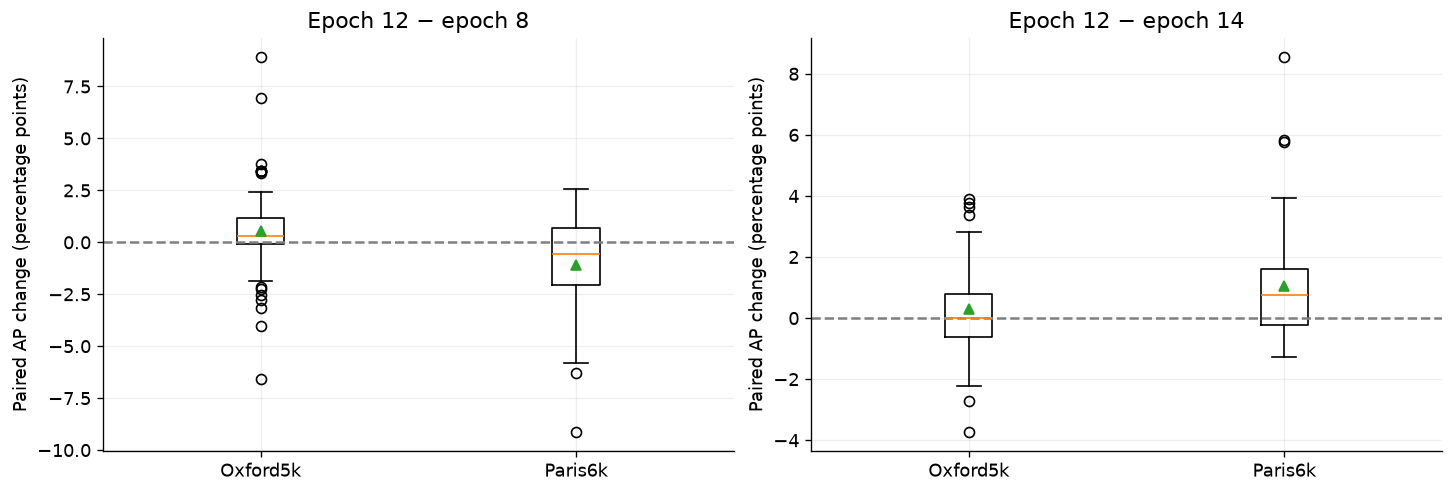

**Diễn giải:** Validation loss và test mAP đo những khía cạnh khác nhau. Paris6k có mAP cao hơn ở epoch 8 so với epoch 12, nhưng checkpoint vẫn chọn theo validation loss. Không thể xác định nguyên nhân query khó là blur, viewpoint hay occlusion chỉ từ AP; cần xem ảnh ở mục 8.

In [7]:
reference_epochs = [e for e in [8, int(history.epoch.max())] if e in saved_evals and e != BEST_EPOCH]
delta_rows, comparison_rows = [], []
for reference in reference_epochs:
    for ds in DATASETS:
        target = np.asarray(selected_eval['datasets'][ds]['aps']) * 100
        other = np.asarray(saved_evals[reference]['datasets'][ds]['aps']) * 100
        delta = target - other
        comparison_rows.append({'dataset': LABELS[ds], 'reference_epoch': reference,
            'selected_epoch': BEST_EPOCH, 'delta_mAP_pp': delta.mean(),
            'queries_improved': int((delta > 1e-8).sum()),
            'queries_declined': int((delta < -1e-8).sum()),
            'queries_unchanged': int((np.abs(delta) <= 1e-8).sum())})
        delta_rows.extend({'dataset': ds, 'reference_epoch': reference, 'query_index_0based': i,
                           'delta_AP_pp': float(v)} for i, v in enumerate(delta))
comparison_table = pd.DataFrame(comparison_rows)
delta_table = pd.DataFrame(delta_rows)
display(comparison_table.round(3))
fig, axes = plt.subplots(1, len(reference_epochs), figsize=(6 * len(reference_epochs), 4),
                          squeeze=False, constrained_layout=True)
for ax, reference in zip(axes.flat, reference_epochs):
    values = [delta_table.loc[(delta_table.dataset == ds) & (delta_table.reference_epoch == reference), 'delta_AP_pp']
              for ds in DATASETS]
    ax.boxplot(values, showmeans=True)
    ax.set_xticks([1, 2], [LABELS[ds] for ds in DATASETS])
    ax.axhline(0, color='gray', linestyle='--')
    ax.set(title=f'Epoch 12 − epoch {reference}', ylabel='Paired AP change (percentage points)')
save_figure(fig, '07_paired_ap_changes')
display(Markdown('**Diễn giải:** Validation loss và test mAP đo những khía cạnh khác nhau. '
                 'Paris6k có mAP cao hơn ở epoch 8 so với epoch 12, nhưng checkpoint vẫn chọn theo validation loss. '
                 'Không thể xác định nguyên nhân query khó là blur, viewpoint hay occlusion chỉ từ AP; cần xem ảnh ở mục 8.'))


## 6. Xuất bảng, hình và ghi chú thuyết trình

PNG phù hợp chèn slide; SVG phù hợp khi cần phóng lớn. CSV giữ số liệu để kiểm tra lại. Báo cáo ghi rõ nguồn saved evaluation, protocol và phạm vi subset. Không gộp Oxford/Paris thành một điểm chung vì đây là hai benchmark riêng.


In [8]:
tables = {'training_history': history, 'run_configuration': config_table,
          'checkpoint_inventory': checkpoint_table, 'map_by_epoch': eval_table,
          'best_epoch_summary': benchmark_summary, 'query_AP_epoch_012': ap_table,
          'query_AP_statistics': ap_stats, 'query_AP_extremes': query_extremes,
          'paired_epoch_comparison': comparison_table, 'paired_query_AP_delta': delta_table}
for name, table in tables.items():
    table.to_csv(OUT_DIR / f'{name}.csv', index=False)

def markdown_table(table, digits=3):
    printable = table.copy()
    for col in printable.select_dtypes(include='number').columns:
        printable[col] = printable[col].map(lambda x: f'{x:.{digits}f}' if isinstance(x, (float, np.floating)) else str(x))
    lines = ['| ' + ' | '.join(map(str, printable.columns)) + ' |',
             '| ' + ' | '.join(['---'] * len(printable.columns)) + ' |']
    lines += ['| ' + ' | '.join(map(str, row)) + ' |' for row in printable.itertuples(index=False, name=None)]
    return '\n'.join(lines)

manifest = {'evidence': 'saved Kaggle evaluation JSON; inference not rerun in sections 1–6',
    'selected_epoch': BEST_EPOCH, 'selection': record['config']['selection'],
    'completed_epochs': int(history.epoch.max()), 'planned_epochs': record['config']['epochs'],
    'source_commit': record['source_commit'], 'best_checkpoint_sha256': sha256(BEST_CHECKPOINT),
    'history_sha256': sha256(RUN_DIR / 'history.json'),
    'evaluation_sha256': sha256(RUN_DIR / f'evaluation_epoch_{BEST_EPOCH:03d}.json'),
    'protocol': selected_eval['protocol'], 'scale': selected_eval['scale'],
    'whitening': False, 'query_expansion': False, 'train_images': train_info['images'],
    'train_clusters': train_info['clusters']}
(OUT_DIR / 'analysis_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
report_text = f"""# B0 VGG16–GeM: kết quả checkpoint epoch 12

Nguồn: artifact Kaggle đã lưu; phần thống kê này không chạy lại inference.
Checkpoint chọn theo validation loss: epoch {BEST_EPOCH}, loss {selected_row.val_loss:.6f}.
Đã hoàn tất {int(history.epoch.max())}/{record['config']['epochs']} epoch trong snapshot.
Training: SfM subset {train_info['clusters']} clusters, {train_info['images']:,} ảnh, seed {record['config']['seed']}.
Protocol: Oxford5k/Paris6k legacy, resize {selected_eval['image_size']}, single-scale, whitening OFF, QE OFF.

## Kết quả chính

{markdown_table(benchmark_summary)}

## Model học như thế nào?

- Training loss: {first.train_loss:.5f} → {last.train_loss:.5f}, giảm {train_drop:.1f}%.
- Validation loss: {first.val_loss:.5f} → {last.val_loss:.5f}, giảm {val_drop:.1f}%.
- Validation loss tốt nhất tại epoch 12; tăng nhẹ ở epoch 13–14, chưa đủ kết luận overfitting.
- GeM p ở checkpoint chọn: {selected_row.gem_p:.4f}, từ initialization {record['config']['gem_p']:.1f}.
- Mean train/val runtime: {history.train_val_minutes.mean():.1f} phút/epoch, không gồm benchmark eval.
- Epoch 15 mới có log từng batch; không đưa vào learning curve như một epoch đã hoàn tất.

![Learning curves](figures/01_learning_curves.png)

![mAP theo epoch](figures/03_map_by_epoch.png)

## Phân bố độ khó theo query

{markdown_table(ap_stats)}

![AP distribution](figures/05_ap_distribution.png)

## So sánh checkpoint

{markdown_table(comparison_table)}

## Gợi ý lời nói trên slide

“Nhóm fine-tune VGG16 với GeM pooling trên SfM subset-100. Model được chọn ở epoch 12 dựa trên validation loss thấp nhất, không dựa vào điểm test. Với single-scale và không whitening hay query expansion, checkpoint này đạt mAP {selected_eval['datasets']['oxford5k']['map_percent']:.2f}% trên Oxford5k và {selected_eval['datasets']['paris6k']['map_percent']:.2f}% trên Paris6k. Loss giảm rõ trong quá trình học, nhưng test mAP không tăng đều ở mọi epoch. Đây là kết quả reproduction trên subset; chưa có ablation để quy toàn bộ mức hiệu năng cho riêng GeM.”

## Giới hạn

- Không có benchmark trước fine-tuning trong artifact để tính mức tăng so với pretrained model.
- Chưa có ranking/ảnh benchmark ở local, nên phần saved analysis không dựng PR curve hoặc ảnh top-k giả định.
- Query cùng landmark có thể tương quan; thống kê AP là mô tả, không phải kiểm định ý nghĩa thống kê.
- Không đối chiếu trực tiếp với điểm paper nếu chưa khớp training data, protocol và post-processing.
- latest.pt là epoch 14; latest_resume.pt ở ngoài run là epoch 7. Nếu resume, kiểm tra đúng file.
"""
(OUT_DIR / 'presentation_summary.md').write_text(report_text, encoding='utf-8')
# Hình đã hiển thị phía trên; liên kết ảnh trong report được giữ tương đối với file .md xuất ra.
display(Markdown(re.sub(r'^!\[.*?\]\(figures/.*?\)\s*$', '', report_text, flags=re.MULTILINE)))
print('Đã xuất', len(tables), 'bảng CSV, manifest, báo cáo và hình PNG/SVG vào', OUT_DIR)


# B0 VGG16–GeM: kết quả checkpoint epoch 12

Nguồn: artifact Kaggle đã lưu; phần thống kê này không chạy lại inference.
Checkpoint chọn theo validation loss: epoch 12, loss 0.103847.
Đã hoàn tất 14/100 epoch trong snapshot.
Training: SfM subset 100 clusters, 15,953 ảnh, seed 42.
Protocol: Oxford5k/Paris6k legacy, resize 1024, single-scale, whitening OFF, QE OFF.

## Kết quả chính

| dataset | epoch | gallery_images | queries | mAP_percent |
| --- | --- | --- | --- | --- |
| Oxford5k | 12 | 5063 | 55 | 81.060 |
| Paris6k | 12 | 6392 | 55 | 77.124 |

## Model học như thế nào?

- Training loss: 0.14836 → 0.08000, giảm 46.1%.
- Validation loss: 0.12907 → 0.10415, giảm 19.3%.
- Validation loss tốt nhất tại epoch 12; tăng nhẹ ở epoch 13–14, chưa đủ kết luận overfitting.
- GeM p ở checkpoint chọn: 2.9641, từ initialization 3.0.
- Mean train/val runtime: 75.5 phút/epoch, không gồm benchmark eval.
- Epoch 15 mới có log từng batch; không đưa vào learning curve như một epoch đã hoàn tất.



## Phân bố độ khó theo query

| dataset | n_queries | mean_AP_percent | median_AP_percent | std_AP_pp | min_AP_percent | q25_AP_percent | q75_AP_percent | max_AP_percent | AP_below_50_count | AP_at_least_90_count |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Oxford5k | 55 | 81.060 | 85.536 | 15.347 | 36.935 | 69.852 | 94.041 | 100.000 | 2 | 16 |
| Paris6k | 55 | 77.124 | 79.693 | 13.776 | 31.054 | 71.001 | 87.609 | 94.153 | 2 | 6 |


## So sánh checkpoint

| dataset | reference_epoch | selected_epoch | delta_mAP_pp | queries_improved | queries_declined | queries_unchanged |
| --- | --- | --- | --- | --- | --- | --- |
| Oxford5k | 8 | 12 | 0.520 | 32 | 15 | 8 |
| Paris6k | 8 | 12 | -1.074 | 22 | 33 | 0 |
| Oxford5k | 14 | 12 | 0.288 | 26 | 21 | 8 |
| Paris6k | 14 | 12 | 1.039 | 38 | 17 | 0 |

## Gợi ý lời nói trên slide

“Nhóm fine-tune VGG16 với GeM pooling trên SfM subset-100. Model được chọn ở epoch 12 dựa trên validation loss thấp nhất, không dựa vào điểm test. Với single-scale và không whitening hay query expansion, checkpoint này đạt mAP 81.06% trên Oxford5k và 77.12% trên Paris6k. Loss giảm rõ trong quá trình học, nhưng test mAP không tăng đều ở mọi epoch. Đây là kết quả reproduction trên subset; chưa có ablation để quy toàn bộ mức hiệu năng cho riêng GeM.”

## Giới hạn

- Không có benchmark trước fine-tuning trong artifact để tính mức tăng so với pretrained model.
- Chưa có ranking/ảnh benchmark ở local, nên phần saved analysis không dựng PR curve hoặc ảnh top-k giả định.
- Query cùng landmark có thể tương quan; thống kê AP là mô tả, không phải kiểm định ý nghĩa thống kê.
- Không đối chiếu trực tiếp với điểm paper nếu chưa khớp training data, protocol và post-processing.
- latest.pt là epoch 14; latest_resume.pt ở ngoài run là epoch 7. Nếu resume, kiểm tra đúng file.


Đã xuất 10 bảng CSV, manifest, báo cáo và hình PNG/SVG vào /home/dacekey/SEG301_Fall26/research/reproduce/evaluation_results/epoch_012


## 7. Chạy lại evaluation từ best.pt — tùy chọn

Đặt `RERUN_BENCHMARK = True` ở mục 1 và điền `BENCHMARK_DIRS` (mỗi thư mục chứa `gnd_oxford5k.pkl`/`gnd_paris6k.pkl` và `jpg/`). Chạy lại tất cả cell từ đầu để tránh giữ biến của lần chạy trước.

Phần này dùng source snapshot đúng run, load toàn bộ checkpoint epoch 12, FP32, `eval()` và `inference_mode()`. Backbone khởi tạo với `pretrained=False` để không tải weights. Dùng `ImagesFromList` của source để giữ đúng crop + resize query: resize crop có xét tỷ lệ kích thước crop với ảnh gốc. Ground truth được kiểm tra SHA256 và kích thước benchmark theo run record.

Chỉ load checkpoint và ground-truth pickle thuộc artifact/dataset tin cậy của nhóm. Kết quả mới được xuất riêng trong `rerun/`, không ghi đè JSON Kaggle. CPU được hỗ trợ nhưng chậm; GPU được dùng nếu có. Đường dẫn Kaggle cũ trong run record không tự có sẵn ở máy local.


In [9]:
rerun_results = {}
if not RERUN_BENCHMARK:
    print('Bỏ qua inference mới: RERUN_BENCHMARK=False. Mục 1–6 dùng saved evaluation.')
else:
    import sys
    import pickle
    import time
    import torch
    from torchvision import transforms

    resolved_benchmark_dirs = {}
    for ds in DATASETS:
        if BENCHMARK_DIRS[ds] is None:
            raise ValueError(f'Cần điền BENCHMARK_DIRS[{ds!r}] trước khi inference.')
        path = Path(BENCHMARK_DIRS[ds]).expanduser().resolve()
        if not (path / f'gnd_{ds}.pkl').is_file() or not (path / 'jpg').is_dir():
            raise FileNotFoundError(f'{path} phải chứa gnd_{ds}.pkl và jpg/.')
        resolved_benchmark_dirs[ds] = path

    # Không trộn cirtorch đã import từ checkout khác với source snapshot của run.
    for module_name, module in list(sys.modules.items()):
        if module_name == 'cirtorch' or module_name.startswith('cirtorch.'):
            origin = getattr(module, '__file__', None)
            if origin and not Path(origin).resolve().is_relative_to(SOURCE_DIR.resolve()):
                raise RuntimeError('cirtorch đã import từ nơi khác. Restart kernel rồi Run All.')
    sys.path.insert(0, str(SOURCE_DIR))
    from cirtorch.networks.imageretrievalnet import init_network
    from cirtorch.datasets.genericdataset import ImagesFromList
    from cirtorch.utils.evaluate import compute_map

    for relative, expected in record['source_hashes'].items():
        if relative.endswith('.py'):
            assert sha256(SOURCE_DIR / relative) == expected, f'Source thay đổi: {relative}'

    checkpoint = torch.load(BEST_CHECKPOINT, map_location='cpu', weights_only=False)
    assert checkpoint['epoch'] == BEST_EPOCH
    meta = checkpoint['meta']
    assert meta['architecture'] == 'vgg16' and meta['pooling'] == 'gem'
    assert meta['outputdim'] == 512
    assert not meta['local_whitening'] and not meta['regional'] and not meta['whitening']
    net = init_network({**meta, 'pretrained': False})
    net.load_state_dict(checkpoint['state_dict'], strict=True)
    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    net = net.to(device).float().eval()
    assert np.isclose(float(net.pool.p.detach().cpu().item()), selected_row.gem_p, atol=1e-6)
    transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(meta['mean'], meta['std'])])
    RERUN_DIR = OUT_DIR / 'rerun'
    RERUN_DIR.mkdir(exist_ok=True)
    print('Device:', device, '| Epoch:', checkpoint['epoch'], '| GeM p:', net.pool.p.item())

    def extract_single_scale(image_paths, bbxs=None):
        dataset = ImagesFromList(root='', images=[str(p) for p in image_paths],
            imsize=selected_eval['image_size'], bbxs=bbxs, transform=transform)
        # num_workers=0 chạy ổn định cả notebook local; batch=1 giữ ảnh có kích thước khác nhau.
        loader = torch.utils.data.DataLoader(dataset, batch_size=1, shuffle=False,
                                             num_workers=0, pin_memory=device.type == 'cuda')
        vectors = np.empty((512, len(dataset)), dtype=np.float32)
        with torch.inference_mode():
            for index, batch in enumerate(loader):
                vector = net(batch.to(device).float()).detach().cpu().numpy().reshape(512)
                assert np.isfinite(vector).all()
                vectors[:, index] = vector
                if (index + 1) % 250 == 0 or index + 1 == len(dataset):
                    print(f'Extracted {index + 1}/{len(dataset)}')
        assert np.allclose(np.linalg.norm(vectors, axis=0), 1, atol=1e-4)
        return vectors

    def standard_topk_metrics(ranks, gnd, ks=(1, 5, 10)):
        # P@k: positives trong k kết quả đầu sau khi bỏ junk, chia cho k.
        # Không dùng giá trị precision nguồn gốc có denominator min(k, last-positive-rank).
        rows = []
        for i, ground in enumerate(gnd):
            positives = np.asarray(ground['ok'], dtype=int)
            junk = np.asarray(ground.get('junk', []), dtype=int)
            cleaned = ranks[:, i][~np.isin(ranks[:, i], junk)]
            row = {'query_index_0based': i}
            for k in ks:
                hits = int(np.isin(cleaned[:k], positives).sum())
                row[f'P@{k}'] = hits / min(k, len(cleaned))
                row[f'Recall@{k}'] = hits / len(positives) if len(positives) else np.nan
            rows.append(row)
        return pd.DataFrame(rows)

    fresh_summary = []
    for ds in DATASETS:
        started = time.perf_counter()
        directory = resolved_benchmark_dirs[ds]
        ground_file = directory / f'gnd_{ds}.pkl'
        assert sha256(ground_file) == record['dataset_identity'][ds]['ground_truth_sha256']
        with ground_file.open('rb') as f:
            cfg = pickle.load(f)
        gallery = [directory / 'jpg' / f'{name}.jpg' for name in cfg['imlist']]
        queries = [directory / 'jpg' / f'{name}.jpg' for name in cfg['qimlist']]
        assert len(gallery) == record['dataset_identity'][ds]['gallery']
        assert len(queries) == len(cfg['gnd']) == record['dataset_identity'][ds]['queries']
        missing = [str(p) for p in gallery + queries if not p.is_file()]
        if missing:
            raise FileNotFoundError(f'{len(missing)} ảnh thiếu; ví dụ {missing[:3]}')
        for ground in cfg['gnd']:
            assert len(ground['ok']) > 0 and 'bbx' in ground
            for key in ['ok', 'junk']:
                inds = np.asarray(ground.get(key, []), dtype=int)
                assert ((inds >= 0) & (inds < len(gallery))).all()
            assert not set(ground['ok']).intersection(ground.get('junk', []))

        print(f'\n{LABELS[ds]}: gallery descriptors')
        gallery_vectors = extract_single_scale(gallery)
        print(f'{LABELS[ds]}: cropped query descriptors')
        query_vectors = extract_single_scale(queries, [g['bbx'] for g in cfg['gnd']])
        scores = gallery_vectors.T @ query_vectors
        ranks = np.argsort(-scores, axis=0)  # Cùng ranking convention với source test.py.
        map_value, aps, _, _ = compute_map(ranks, cfg['gnd'])
        assert np.isclose(map_value, np.mean(aps))
        topk = standard_topk_metrics(ranks, cfg['gnd'])
        saved_aps = np.asarray(selected_eval['datasets'][ds]['aps'])
        result = {'dataset': ds, 'epoch': BEST_EPOCH, 'evidence': 'fresh checkpoint inference',
            'checkpoint_sha256': manifest['best_checkpoint_sha256'], 'source_commit': record['source_commit'],
            'image_size': selected_eval['image_size'], 'scale': [1], 'whitening': False,
            'query_expansion': False, 'protocol': 'legacy_ok_junk', 'map': float(map_value),
            'map_percent': float(map_value * 100), 'aps': aps.tolist(),
            'seconds': time.perf_counter() - started, 'device': str(device),
            'torch': torch.__version__, 'max_abs_AP_delta_vs_saved': float(np.max(np.abs(aps - saved_aps))),
            'topk_mean': {k: float(v) for k, v in topk.drop(columns='query_index_0based').mean().items()}}
        (RERUN_DIR / f'{ds}_evaluation.json').write_text(json.dumps(result, indent=2))
        np.savez_compressed(RERUN_DIR / f'{ds}_descriptors_ranks.npz',
                            gallery=gallery_vectors, query=query_vectors, ranks=ranks)
        topk.to_csv(RERUN_DIR / f'{ds}_query_topk.csv', index=False)
        pd.DataFrame({'query_index_0based': np.arange(len(aps)), 'query_name': cfg['qimlist'],
                      'AP_percent': aps * 100}).to_csv(RERUN_DIR / f'{ds}_named_query_AP.csv', index=False)
        rerun_results[ds] = {'cfg': cfg, 'gallery': gallery, 'queries': queries,
                             'ranks': ranks, 'scores': scores, 'aps': aps, 'result': result}
        fresh_summary.append({'dataset': LABELS[ds], 'fresh_mAP_percent': map_value * 100,
            'saved_mAP_percent': selected_eval['datasets'][ds]['map_percent'],
            'delta_mAP_pp': map_value * 100 - selected_eval['datasets'][ds]['map_percent'],
            **result['topk_mean']})
    fresh_summary_table = pd.DataFrame(fresh_summary)
    fresh_summary_table.to_csv(RERUN_DIR / 'fresh_vs_saved_summary.csv', index=False)
    display(fresh_summary_table.round(5))
    print('Nếu fresh khác saved, kiểm tra crop/resize, source, FP32 và môi trường; không ghi đè kết quả cũ.')


Bỏ qua inference mới: RERUN_BENCHMARK=False. Mục 1–6 dùng saved evaluation.


## 8. Precision–recall và ảnh retrieval thực tế

Chỉ chạy khi mục 7 tạo ranking mới. Với mỗi benchmark, chọn query có AP thấp nhất, AP gần median và AP cao nhất để minh họa. Chọn theo AP và ghi rõ cách chọn; không coi ba query là đại diện thống kê cho toàn bộ tập.

PR curve dưới đây là đường precision tại các vị trí ranking sau khi loại `junk`. Legend dùng AP từ phép tính hình thang của source; diện tích của đường vẽ dạng step không nhất thiết bằng đúng AP legacy. Top-5 cũng loại `junk`; viền xanh là positive (`ok`), đỏ là negative. Quan sát ảnh để đề xuất giả thuyết lỗi, không suy nguyên nhân từ AP đơn thuần.


In [10]:
if not rerun_results:
    print('Chưa có ranking/ảnh: bật RERUN_BENCHMARK và cung cấp dataset để tạo PR curves và top-5 retrieval.')
else:
    from PIL import Image

    def representative_queries(aps):
        choices = [('lowest AP', int(np.argmin(aps))),
                   ('near median AP', int(np.argmin(np.abs(aps - np.median(aps))))),
                   ('highest AP', int(np.argmax(aps)))]
        return choices

    def load_preview(path, bbox=None):
        with Image.open(path) as image:
            image = image.convert('RGB')
            if bbox is not None:
                image = image.crop(bbox)
            image.thumbnail((360, 280), Image.Resampling.LANCZOS)
            return image.copy()

    for ds, data in rerun_results.items():
        cfg, ranks, aps = data['cfg'], data['ranks'], data['aps']
        choices = representative_queries(aps)
        fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
        for description, qi in choices:
            ground = cfg['gnd'][qi]
            cleaned = ranks[:, qi][~np.isin(ranks[:, qi], ground.get('junk', []))]
            relevant = np.isin(cleaned, ground['ok']).astype(int)
            cumulative = np.cumsum(relevant)
            precision = cumulative / np.arange(1, len(cleaned) + 1)
            recall = cumulative / len(ground['ok'])
            ax.step(np.r_[0, recall], np.r_[1, precision], where='post',
                    label=f'{description}: q{qi}, AP={aps[qi] * 100:.2f}%')
        ax.set(xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1.03),
               title=f'{LABELS[ds]} | selected-query PR curves (epoch 12)')
        ax.legend(fontsize=9)
        save_figure(fig, f'08_{ds}_precision_recall')

        for description, qi in choices:
            ground = cfg['gnd'][qi]
            cleaned = ranks[:, qi][~np.isin(ranks[:, qi], ground.get('junk', []))]
            fig, axes = plt.subplots(1, 6, figsize=(16, 3.8), constrained_layout=True)
            axes[0].imshow(load_preview(data['queries'][qi], ground['bbx']))
            axes[0].set_title('Cropped query', fontsize=10)
            axes[0].axis('off')
            for rank_no, (ax, gi) in enumerate(zip(axes[1:], cleaned[:5]), start=1):
                positive = gi in ground['ok']
                ax.imshow(load_preview(data['gallery'][gi]))
                ax.set_title(f'#{rank_no}: {"positive" if positive else "negative"}', fontsize=10)
                ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
                for spine in ax.spines.values():
                    spine.set_visible(True); spine.set_color('#059669' if positive else '#dc2626'); spine.set_linewidth(3)
            fig.suptitle(f'{LABELS[ds]} | {description} | {cfg["qimlist"][qi]} | AP={aps[qi] * 100:.2f}%')
            save_figure(fig, f'09_{ds}_query_{qi:03d}_top5')


Chưa có ranking/ảnh: bật RERUN_BENCHMARK và cung cấp dataset để tạo PR curves và top-5 retrieval.


## 9. Chọn tư liệu cho bài thuyết trình

| Slide | Tư liệu | Ý cần nói |
| --- | --- | --- |
| Cấu hình reproduction | `run_configuration.csv` | VGG16–GeM, subset-100, selection theo validation loss |
| Quá trình học | `01_learning_curves.png` | Loss giảm, `p` được học, validation chững lại sau epoch 12 |
| Kết quả chính | `04_best_epoch_map.png` | Oxford5k 81.06%, Paris6k 77.12%, protocol legacy |
| Diễn biến retrieval | `03_map_by_epoch.png` | mAP không tăng đều, test mAP không quyết định chọn model |
| Query khó/dễ | `05_ap_distribution.png`, `06_ap_per_query.png` | Một mAP không thể hiện toàn bộ độ khó từng query |
| Minh họa trực quan (nếu chạy lại) | `08_*`, `09_*` | PR curves và top-5 thật; mô tả điểm thành công/thất bại |

**Nguồn:** `run_record.json`, `history.json`, `evaluation_epoch_008...014.json`, `best.pt`, source snapshot `747166e627e5`. Phương pháp: [Fine-tuning CNN Image Retrieval with No Human Annotation](../../paper/GeM.pdf), mục 3; [specification B0](../../IIR-Robust-Retrieval/report/B0/B0_GeM.md).

**Kết luận được dữ liệu hỗ trợ:** Nhóm đã chạy fine-tuning và có checkpoint cho kết quả retrieval trên hai benchmark. Trong snapshot hiện có, epoch 12 là model được chọn theo validation loss. Muốn kết luận GeM tốt hơn average/max pooling hoặc model robust với biến đổi ảnh, cần các thí nghiệm đối chứng tương ứng.
